In [ ]:
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
from torchvision import transforms

import torch
import torch.nn as nn
import torch.optim as optim

from torch.utils.data import TensorDataset, DataLoader

from sklearn.model_selection import train_test_split
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.metrics import accuracy_score

from time import time

torch.manual_seed(42)


device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("PyTorch:", torch.__version__)
print("CUDA:", torch.version.cuda)
print("Dispositivo:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("VRAM:", round(torch.cuda.get_device_properties(0).total_memory / 1024**3, 2), "GB")

PyTorch: 2.8.0+cu128
CUDA: 12.8
Dispositivo: cuda
GPU: NVIDIA GeForce RTX 3070 Laptop GPU
VRAM: 8.0 GB


In [12]:
a = torch.rand(1000, 1000).to(device)
b = torch.rand(1000, 1000).to(device)

c = a @ b

print("Resultado:", c.shape)
print("Dispositivo utilizado:", c.device)

Resultado: torch.Size([1000, 1000])
Dispositivo utilizado: cuda:0


In [ ]:
def LoadDataset(folder, ext):

    nclasses = 0
    nperclass = []
    classlabels = []

    X = []
    Y = []

    
    for class_name in sorted(os.listdir(folder)):

        class_folder = os.path.join(folder, class_name)

        if not os.path.isdir(class_folder):
            continue

        nclasses += 1
        nsamples = 0

        for file_name in os.listdir(class_folder):

            if file_name.lower().endswith(ext):

                # Lee la imagen en escala de grises
                gray = cv2.imread(
                    os.path.join(class_folder, file_name),
                    cv2.IMREAD_GRAYSCALE
                )

                if gray is None:
                    continue

                gray = cv2.resize(gray, (48, 48))

                # Añade la imagen convertida en vector
                X.append(gray.reshape(48 * 48))

                # Añade etiqueta numerica
                Y.append(nclasses - 1)

                nsamples += 1

        nperclass.append(nsamples)
        classlabels.append(class_name)

    return X, Y, nperclass, classlabels

In [14]:
folder_train = "FER2013/train"
folder_test = "FER2013/test"

ext = (".jpg", ".jpeg", ".png")

print("Cargando entrenamiento...")

X_train, y_train, nperclass_train, class_names = LoadDataset(
    folder_train, ext
)

print("Cargando test...")

X_test, y_test, nperclass_test, class_names_test = LoadDataset(
    folder_test, ext
)

assert class_names == class_names_test

# Convertir a arrays de NumPy
X_train = np.array(X_train, dtype="uint8")
X_test = np.array(X_test, dtype="uint8")

y_train = np.array(y_train)
y_test = np.array(y_test)

# Separar entrenamiento y validacion
X_train, X_val, y_train, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    random_state=42,
    stratify=y_train
)

# Recuperar las dimensiones de las imagenes y normalizar
X_train = torch.tensor(X_train).reshape(-1, 1, 48, 48).float() / 255
X_val = torch.tensor(X_val).reshape(-1, 1, 48, 48).float() / 255
X_test = torch.tensor(X_test).reshape(-1, 1, 48, 48).float() / 255

# Convertir las etiquetas a tensores
y_train = torch.tensor(y_train, dtype=torch.long)
y_val = torch.tensor(y_val, dtype=torch.long)
y_test = torch.tensor(y_test, dtype=torch.long)

print("Entrenamiento:", X_train.shape)
print("Validacion:", X_val.shape)
print("Test:", X_test.shape)
print("Clases:", class_names)

Cargando entrenamiento...
Cargando test...
Entrenamiento: torch.Size([24402, 1, 48, 48])
Validacion: torch.Size([4307, 1, 48, 48])
Test: torch.Size([7178, 1, 48, 48])
Clases: ['angry', 'disgust', 'fear', 'happy', 'neutral', 'sad', 'surprise']


In [15]:
# Transformaciones aleatorias de las imagenes
augmentation = transforms.Compose([
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomAffine(
        degrees=10,
        translate=(0.08, 0.08),
        scale=(0.9, 1.1)
    )
])


class AugmentedDataset(TensorDataset):

    def __getitem__(self, index):

        image, label = super().__getitem__(index)

        image = augmentation(image)

        return image, label


batch_size = 128

train_dataset = AugmentedDataset(X_train, y_train)
val_dataset = TensorDataset(X_val, y_val)
test_dataset = TensorDataset(X_test, y_test)

train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    pin_memory=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=batch_size,
    shuffle=False,
    pin_memory=True
)

print("Batches de entrenamiento:", len(train_loader))
print("Batches de validacion:", len(val_loader))
print("Batches de test:", len(test_loader))

Batches de entrenamiento: 191
Batches de validacion: 34
Batches de test: 57


In [16]:
class CNN(nn.Module):

    def __init__(self):
        super().__init__()

        self.red = nn.Sequential(

            # Primer bloque convolucional
            nn.Conv2d(1, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.Conv2d(32, 32, kernel_size=3, padding=1),
            nn.BatchNorm2d(32),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout2d(0.1),

            # Segundo bloque convolucional
            nn.Conv2d(32, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.Conv2d(64, 64, kernel_size=3, padding=1),
            nn.BatchNorm2d(64),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout2d(0.2),

            # Tercer bloque convolucional
            nn.Conv2d(64, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.Conv2d(128, 128, kernel_size=3, padding=1),
            nn.BatchNorm2d(128),
            nn.ReLU(),

            nn.MaxPool2d(2),
            nn.Dropout2d(0.3),

            # Clasificacion
            nn.Flatten(),

            nn.Linear(128 * 6 * 6, 128),
            nn.ReLU(),
            nn.Dropout(0.5),

            nn.Linear(128, 7)
        )

    def forward(self, x):
        return self.red(x)


torch.manual_seed(42)

modelo_cnn = CNN().to(device)

print(modelo_cnn)
print("Dispositivo:", next(modelo_cnn.parameters()).device)

CNN(
  (red): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU()
    (3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU()
    (6): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (7): Dropout2d(p=0.1, inplace=False)
    (8): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (9): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (10): ReLU()
    (11): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (12): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (13): ReLU()
    (14): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (15): Dropout2d(p=0.2, inplace=False)

In [ ]:
# Calcular los pesos de cada clase
conteos = torch.bincount(y_train).float()

pesos = 1.0 / torch.sqrt(conteos)
pesos = pesos / pesos.mean()
pesos = pesos.to(device)

for i in range(len(class_names)):
    print(
        class_names[i],
        "- Muestras:", int(conteos[i]),
        "- Peso:", round(pesos[i].item(), 3)
    )

criterio = nn.CrossEntropyLoss(weight=pesos)

optimizer = optim.Adam(
    modelo_cnn.parameters(),
    lr=0.001,
    weight_decay=0.0001
)

scheduler = optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=3,
    min_lr=0.00001
)

epochs = 50

train_losses = []
val_losses = []

train_accuracies = []
val_accuracies = []

mejor_val_loss = float("inf")
mejores_pesos = None

patience = 10
sin_mejora = 0

t0 = time()

for epoch in range(epochs):

    # ENTRENAMIENTO
    modelo_cnn.train()

    loss_total = 0
    peso_total = 0
    correctos = 0

    for images, labels in train_loader:

        
        images = images.to(device)
        labels = labels.to(device)

        
        optimizer.zero_grad()

        
        outputs = modelo_cnn(images)

        
        loss = criterio(outputs, labels)

        
        loss.backward()

        
        optimizer.step()

        
        peso_batch = pesos[labels].sum().item()
        loss_total += loss.item() * peso_batch
        peso_total += peso_batch

        pred = outputs.argmax(dim=1)
        correctos += (pred == labels).sum().item()

    train_loss = loss_total / peso_total
    train_acc = correctos / len(train_dataset)

    # VALIDACION
    modelo_cnn.eval()

    loss_total = 0
    peso_total = 0
    correctos = 0

    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(device)
            labels = labels.to(device)

            outputs = modelo_cnn(images)

            loss = criterio(outputs, labels)

            peso_batch = pesos[labels].sum().item()
            loss_total += loss.item() * peso_batch
            peso_total += peso_batch

            pred = outputs.argmax(dim=1)
            correctos += (pred == labels).sum().item()

    val_loss = loss_total / peso_total
    val_acc = correctos / len(val_dataset)

    
    scheduler.step(val_loss)

    
    train_losses.append(train_loss)
    val_losses.append(val_loss)

    train_accuracies.append(train_acc)
    val_accuracies.append(val_acc)

    print(
        f"Epoch {epoch+1}/{epochs} | "
        f"Train loss: {train_loss:.4f} | "
        f"Train acc: {train_acc:.4f} | "
        f"Val loss: {val_loss:.4f} | "
        f"Val acc: {val_acc:.4f} | "
        f"LR: {optimizer.param_groups[0]['lr']:.6f}"
    )

    # Early Stopping
    if val_loss < mejor_val_loss:

        mejor_val_loss = val_loss

        mejores_pesos = {
            k: v.detach().cpu().clone()
            for k, v in modelo_cnn.state_dict().items()
        }

        sin_mejora = 0

    else:

        sin_mejora += 1

        if sin_mejora >= patience:
            print("Early Stopping")
            break

# Recuperar el mejor modelo
modelo_cnn.load_state_dict(mejores_pesos)
modelo_cnn.eval()

if device.type == "cuda":
    torch.cuda.synchronize()

tiempo_entrenamiento = time() - t0

print("Entrenamiento finalizado")
print("Tiempo:", round(tiempo_entrenamiento, 2), "segundos")

angry - Muestras: 3396 - Peso: 0.806
disgust - Muestras: 371 - Peso: 2.438
fear - Muestras: 3482 - Peso: 0.796
happy - Muestras: 6133 - Peso: 0.6
neutral - Muestras: 4220 - Peso: 0.723
sad - Muestras: 4105 - Peso: 0.733
surprise - Muestras: 2695 - Peso: 0.905
Epoch 1/50 | Train loss: 1.9160 | Train acc: 0.2277 | Val loss: 1.8607 | Val acc: 0.2779 | LR: 0.001000
Epoch 2/50 | Train loss: 1.8713 | Train acc: 0.2555 | Val loss: 1.7699 | Val acc: 0.3216 | LR: 0.001000
Epoch 3/50 | Train loss: 1.8085 | Train acc: 0.2916 | Val loss: 1.7053 | Val acc: 0.3740 | LR: 0.001000
Epoch 4/50 | Train loss: 1.7384 | Train acc: 0.3283 | Val loss: 1.6326 | Val acc: 0.3987 | LR: 0.001000
Epoch 5/50 | Train loss: 1.6873 | Train acc: 0.3521 | Val loss: 1.5865 | Val acc: 0.4247 | LR: 0.001000
Epoch 6/50 | Train loss: 1.6620 | Train acc: 0.3636 | Val loss: 1.5541 | Val acc: 0.3996 | LR: 0.001000
Epoch 7/50 | Train loss: 1.6410 | Train acc: 0.3707 | Val loss: 1.5307 | Val acc: 0.4186 | LR: 0.001000
Epoch 8/50 |

In [18]:
torch.save(
    {
        "model_state_dict": modelo_cnn.state_dict(),
        "class_names": [str(c) for c in class_names],
        "image_size": (48, 48)
    },
    "modelo_cnn_mejorado.pth"
)

print("Modelo CNN guardado correctamente")

Modelo CNN guardado correctamente


In [19]:
modelo_cnn.eval()

y_pred = []
y_real = []

if device.type == "cuda":
    torch.cuda.synchronize()

t0 = time()

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(device)

        outputs = modelo_cnn(images)

        pred = outputs.argmax(dim=1)

        y_pred.extend(pred.cpu().numpy())
        y_real.extend(labels.numpy())

if device.type == "cuda":
    torch.cuda.synchronize()

tiempo_prediccion = time() - t0

print("Accuracy:", accuracy_score(y_real, y_pred) * 100, "%")
print("Tiempo de prediccion:", tiempo_prediccion, "s")

print(classification_report(
    y_real,
    y_pred,
    labels=range(len(class_names)),
    target_names=class_names,
    zero_division=0
))

Accuracy: 62.53831150738367 %
Tiempo de prediccion: 0.3905308246612549 s
              precision    recall  f1-score   support

       angry       0.53      0.56      0.54       958
     disgust       0.49      0.42      0.45       111
        fear       0.46      0.25      0.32      1024
       happy       0.84      0.88      0.86      1774
     neutral       0.59      0.60      0.60      1233
         sad       0.46      0.56      0.50      1247
    surprise       0.73      0.80      0.76       831

    accuracy                           0.63      7178
   macro avg       0.59      0.58      0.58      7178
weighted avg       0.62      0.63      0.62      7178



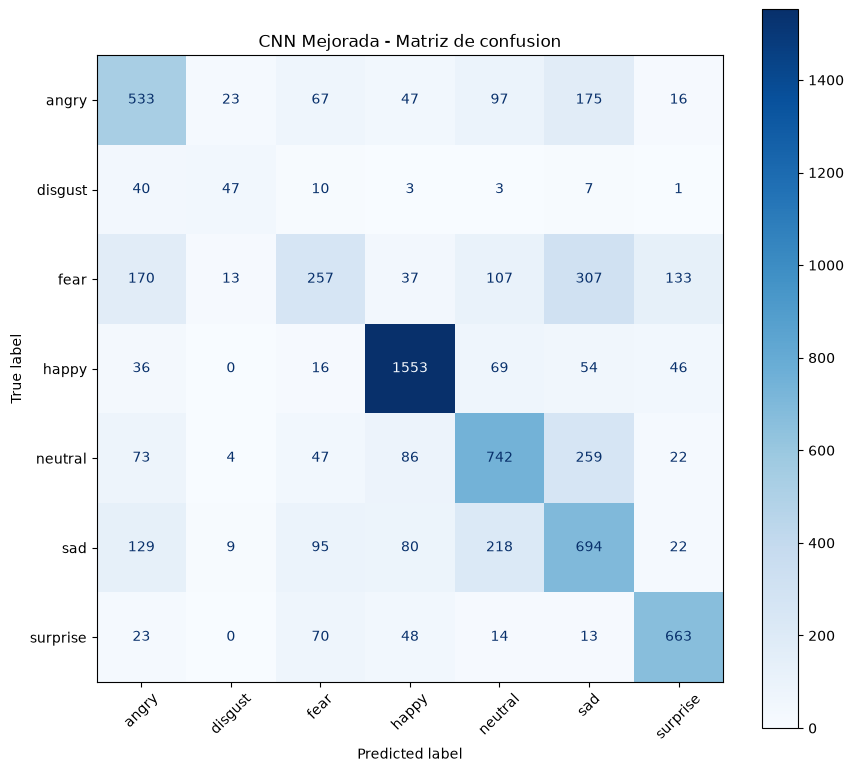

In [20]:
cm = confusion_matrix(
    y_real, y_pred,
    labels=range(len(class_names))
)

fig, ax = plt.subplots(figsize=(9, 8))

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=class_names
)

disp.plot(
    ax=ax,
    cmap="Blues",
    xticks_rotation=45
)

plt.title("CNN Mejorada - Matriz de confusion")
plt.tight_layout()
plt.savefig("matriz_confusion_cnn_mejorado.png", dpi=150)
plt.show()